In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/insurance.csv")

df = df.drop_duplicates()

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 30, 40, 50, 60, 100],
    labels=[
        "Young Adult",
        "Adult",
        "Middle Aged",
        "Senior",
        "Older"
    ]
)

In [4]:
df[["age", "age_group"]].head(10)

,age,age_group
0,19,Young Adult
1,18,Young Adult
2,28,Young Adult
3,33,Adult
4,32,Adult
5,31,Adult
6,46,Middle Aged
7,37,Adult
8,37,Adult
9,60,Senior


In [8]:
df["age_group"].value_counts()

age_group
Young Adult    443
Middle Aged    281
Senior         265
Adult          257
Older           91
Name: count, dtype: int64

In [9]:
df.groupby("age_group")["charges"].mean()

age_group
Young Adult     9415.064442
Adult          11639.308653
Middle Aged    14782.043077
Senior         17062.292763
Older          21063.163398
Name: charges, dtype: float64

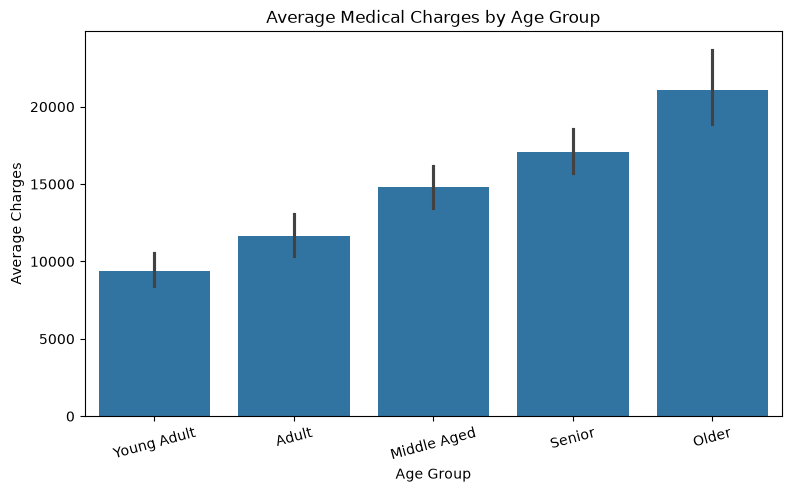

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="age_group",
    y="charges",
    order=[
        "Young Adult",
        "Adult",
        "Middle Aged",
        "Senior",
        "Older"
    ]
)

plt.title("Average Medical Charges by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Charges")
plt.xticks(rotation=15)
plt.show()

In [20]:
age_smoker_analysis = df.groupby(
    ["age_group", "smoker"],
)["charges"].mean().unstack()

age_smoker_analysis

smoker,no,yes
age_group,,
Young Adult,4470.419842,27528.078343
Adult,6631.046417,30466.664836
Middle Aged,9622.055472,33391.834441
Senior,12975.178672,38762.922341
Older,15366.613482,38929.615407


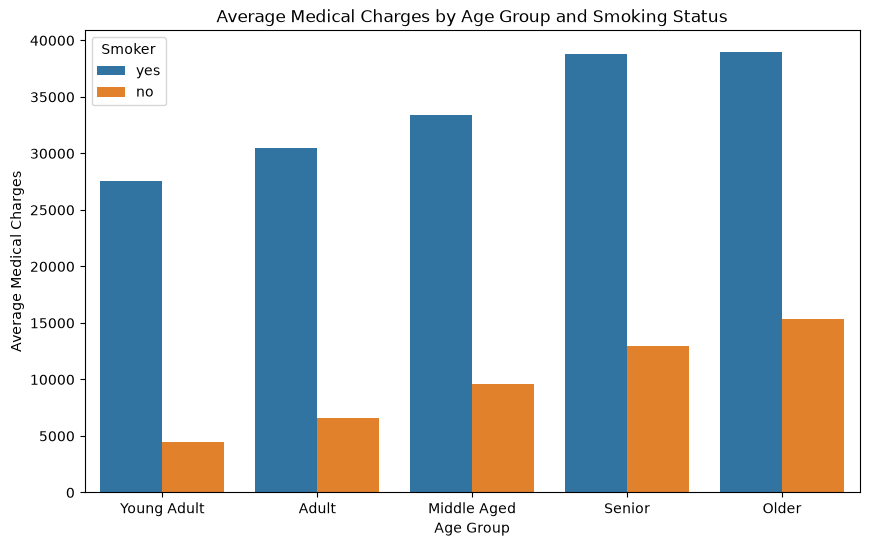

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="age_group",
    y="charges",
    hue="smoker",
    order=[
        "Young Adult",
        "Adult",
        "Middle Aged",
        "Senior",
        "Older"
    ],
    errorbar=None
)

plt.title("Average Medical Charges by Age Group and Smoking Status")
plt.xlabel("Age Group")
plt.ylabel("Average Medical Charges")
plt.legend(title="Smoker")
plt.show()

In [14]:
df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=[
        "Underweight",
        "Normal",
        "Overweight",
        "Obese"
    ]
)

df[["bmi", "bmi_category"]].head(10)

,bmi,bmi_category
0,27.900,Overweight
1,33.770,Obese
2,33.000,Obese
3,22.705,Normal
4,28.880,Overweight
5,25.740,Overweight
6,33.440,Obese
7,27.740,Overweight
8,29.830,Overweight
9,25.840,Overweight


In [15]:
df["bmi_category"].value_counts()

bmi_category
Obese          704
Overweight     386
Normal         226
Underweight     21
Name: count, dtype: int64

In [21]:
df.groupby("bmi_category")["charges"].mean()

bmi_category
Underweight     8657.620652
Normal         10435.440719
Overweight     10997.803881
Obese          15580.700985
Name: charges, dtype: float64

In [22]:
bmi_smoker_analysis = df.groupby(
    ["bmi_category", "smoker"],
    observed=True
)["charges"].mean().unstack()

bmi_smoker_analysis

smoker,no,yes
bmi_category,,
Underweight,5485.056800,18809.824980
Normal,7734.650116,19942.223641
Overweight,8226.088675,22491.182935
Obese,8866.158926,41692.808992
